## Plotting the SPE template

Channel 0
Maximum ADC: 7.80
Peak time: 6.312 µs
Channel 7
Maximum ADC: 14.78
Peak time: 6.328 µs


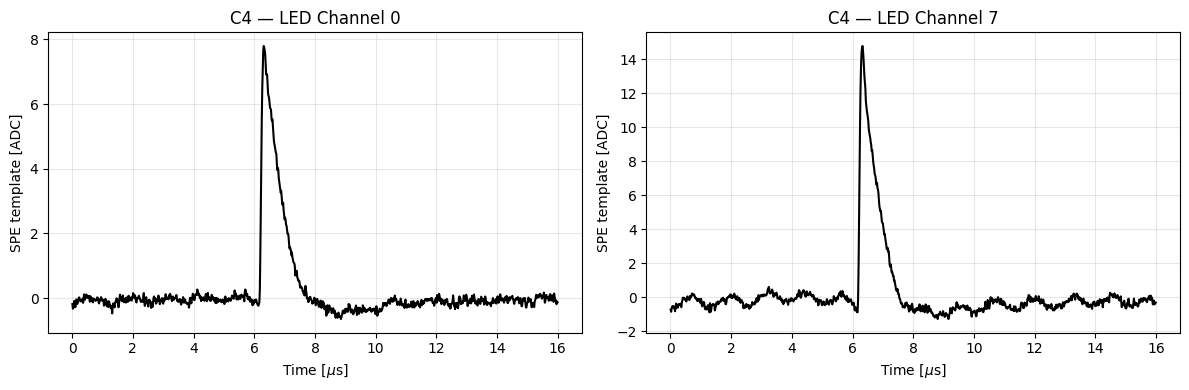

In [1]:
import uproot
import numpy as np
import matplotlib.pyplot as plt

folder = "/Users/rtluanga/myenv/NeutronLab/LED/Calibration_Ajib"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, channel in zip(axes, [0, 7]):

    filename = f"{folder}/C4_AFE3_ch{channel}_SPE.root"

    with uproot.open(filename) as f:
        spe, edges = f["SPEtemplate_ns"].to_numpy()

    time = (edges[:-1] + edges[1:]) / 2 / 1000  # ns -> µs

    ax.plot(time, spe, color="black")

    ax.set_title(f"C4 — LED Channel {channel}")
    ax.set_xlabel(r"Time [$\mu$s]")
    ax.set_ylabel("SPE template [ADC]")
    ax.grid(alpha=0.3)

    print(f"Channel {channel}")
    print(f"Maximum ADC: {np.max(spe):.2f}")
    print(f"Peak time: {time[np.argmax(spe)]:.3f} µs")

plt.tight_layout()
plt.show()

In [2]:
import uproot

for channel in [0, 7]:

    filename = f"{folder}/C4_AFE3_ch{channel}_SPE.root"

    with uproot.open(filename) as f:

        print(f"\nC4 Channel {channel}")

        for key in f.keys():
            print(key, ":", f[key].classname)


C4 Channel 0
timevssignalSPE;1 : TH2D
timevssignalSPE_clean;1 : TH2D
SPEtemplate_profile_ticks;1 : TProfile
SPEtemplate_ns;1 : TH1D

C4 Channel 7
timevssignalSPE;1 : TH2D
timevssignalSPE_clean;1 : TH2D
SPEtemplate_profile_ticks;1 : TProfile
SPEtemplate_ns;1 : TH1D


## PNS/COSMIC Input

In [3]:
import glob

folder = '/Users/rtluanga/myenv/NeutronLab/LED'
cos_tree = "PNSCRPanalyzercosmics/Event"
pns_tree = "PNSCRPanalyzerflashes1/Event"

cos_files = glob.glob(f"{folder}/ana_cosmic_*.root")
cos_with_tree = [f"{f}:{cos_tree}" for f in cos_files]

pns_files = glob.glob(f"{folder}/ana_pns_*.root")
pns_with_tree = [f"{f}:{pns_tree}" for f in pns_files]


In [4]:
def c4_pairs(t, ch, pe):

    a = np.where((ch == 4) & (pe >= 15))[0]
    b = np.where((ch == 7) & (pe >= 15))[0]

    a = a[np.argsort(t[a])]
    b = b[np.argsort(t[b])]

    matched = []
    i, j = 0, 0

    while i < len(a) and j < len(b):

        dt = t[a[i]] - t[b[j]]

        if abs(dt) <= 0.080:   # Peak time differeces in ns (cuts)

            if 100 <= pe[a[i]] + pe[b[j]] <= 2100:
                matched.append((t[a[i]], t[b[j]]))

            i += 1
            j += 1

        elif dt < 0:
            i += 1

        else:
            j += 1

    return matched

In [5]:
def collect_c4_events(files, tree_path):

    selected = []

    for filename in sorted(files):

        with uproot.open(filename) as f:
            data = f[tree_path].arrays(
                ["vtime", "vchannel", "vpeak"],
                library="ak"
            )
            print(tree_path,data["vchannel"])   

        for ev in range(len(data)):

            t = np.asarray(data["vtime"][ev])
            ch = np.asarray(data["vchannel"][ev], dtype=int)
            pe = np.asarray(data["vpeak"][ev])

            pairs = c4_pairs(t, ch, pe)

            for t4, t7 in pairs:
                selected.append((filename, ev, t4, t7))

    return selected


pns_c4 = collect_c4_events(pns_files, pns_tree)
cosmic_c4 = collect_c4_events(cos_files, cos_tree)

print("PNS C4 coincidences:", len(pns_c4))
print("Cosmic C4 coincidences:", len(cosmic_c4))
#print("First PNS coincidence:", pns_c4[1])

PNSCRPanalyzerflashes1/Event [[4, 1, 1, 4, 7, 0, 5, 6, 0, 7, 4, ..., 2, 4, 7, 4, 0, 1, 0, 1, 1, 0, 1], ...]
PNSCRPanalyzerflashes1/Event [[1, 2, 7, 1, 6, 0, 1, 5, 1, 0, 2, ..., 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1], ...]
PNSCRPanalyzerflashes1/Event [[2, 3, 1, 0, 5, 7, 6, 4, 0, 0, 0, ..., 4, 0, 1, 0, 2, 1, 1, 1, 0, 1, 0], ...]
PNSCRPanalyzerflashes1/Event [[7, 4, 4, 5, 0, 1, 3, 7, 2, 3, 7, ..., 1, 0, 0, 2, 0, 1, 2, 0, 7, 4, 0], ...]
PNSCRPanalyzercosmics/Event [[1, 2, 3, 0, 0, 1, 0, 1, 1, 0, 4, ..., 1, 1, 4, 7, 5, 6, 0, 1, 0, 0, 1], ...]
PNSCRPanalyzercosmics/Event [[3, 2, 6, 3, 0, 1, 0, 1, 0, 1, 1, ..., 6, 5, 1, 0, 1, 0, 1, 0, 1, 0, 1], ...]
PNSCRPanalyzercosmics/Event [[1, 1, 0, 0, 3, 3, 1, 5, 6, 3, 2, ..., 1, 1, 0, 4, 1, 0, 1, 1, 0, 1, 0], ...]
PNSCRPanalyzercosmics/Event [[4, 7, 1, 1, 0, 1, 0, 5, 6, 0, 1, ..., 5, 1, 0, 6, 5, 7, 4, 1, 0, 1, 1], ...]
PNS C4 coincidences: 2269
Cosmic C4 coincidences: 693


## Deconvolution

#### Checking Rising Edge

In [30]:
spe = spe - np.mean(spe[250:350])

# Print the SPE samples around the rising edge
print(f"\nChannel {channel}")
print("Sample    SPE amplitude (ADC)")

for i in range(380, 395):
    print(f"{i:4d}      {spe[i]:.3f}")


print(f"Numer of SPE sample",len(spe))
peak_idx = np.argmax(spe)
# Find the first sample reaching 10% of the SPE maximum
onset_idx = np.where(spe[:peak_idx+1] >= 0.1 * spe[peak_idx])[0][0]

print(f"\nSPE peak: sample {peak_idx}")
print(f"10% rising edge: sample {onset_idx}")
print(f"Suggested crop: sample {onset_idx - 1}")


Channel 7
Sample    SPE amplitude (ADC)
 380      -0.645
 381      -0.539
 382      -0.701
 383      -0.785
 384      -0.836
 385      -0.824
 386      -0.029
 387      1.883
 388      4.726
 389      7.499
 390      10.181
 391      12.299
 392      13.587
 393      14.408
 394      14.707
Numer of SPE sample 1000

SPE peak: sample 395
10% rising edge: sample 387
Suggested crop: sample 386


### Note:
 * The SPE template contains 1000 samples
 * We use samples 250-349 to estimate its baseline because they occur before the LED pulse
 * This centered(approximately) the SPE template around 0
 * Shift the SPE pulse at the begining of the template i.e 386

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import uproot

DT = 0.016  # microsecond -> ADC sampling interval

spe_folder = "/Users/rtluanga/myenv/NeutronLab/LED/Calibration_Ajib"

# Load SPE templates
spe_templates = {}

for channel, led_channel in [(4, 0), (7, 7)]:

    file = f"{spe_folder}/C4_AFE3_ch{led_channel}_SPE.root"

    with uproot.open(file) as f:
        spe, edges = f["SPEtemplate_ns"].to_numpy()

    # Subtract template baseline
    spe = spe - np.mean(spe[250:350])

    # Align the SPE onset to sample zero
    spe_templates[channel] = spe[386:]

##### Wiener deconvolution (lamda = 0.02)-> Tunable

In [33]:
def deconvolve(waveform, spe, reg=0.02):

    n = len(waveform) + len(spe) - 1

    W = np.fft.rfft(waveform, n=n)
    H = np.fft.rfft(spe, n=n)

    power = np.abs(H)**2

    S = W * np.conj(H) / (power + reg * power.max())

    result = np.fft.irfft(S, n=n)

    return result[:len(waveform)]


#### Checking python FFT

In [36]:
import numpy as np

waveform = np.array([0, 1, 3, 5, 3, 1, 0], dtype=float)

W = np.fft.rfft(waveform)

reconstructed = np.fft.irfft(W, n=len(waveform))

print("Original:", waveform)
print("Reconstructed:", np.round(reconstructed, 6))

Original: [0. 1. 3. 5. 3. 1. 0.]
Reconstructed: [-0.  1.  3.  5.  3.  1.  0.]


### Note:
 * tp = reconstructed ADC peak (ms)
 * DT = sampling interval (16ns)
 * pk = ADC sample number corrsponding to the peak
 * before_peak = include waveform the ADC peak (ms)
 * after_peak = include waveform after the ADC peak (ms)

In [75]:
revent = 1
before_peak = 125 #(i.e 125 x 0.016 = 2 ms)
after_peak = 300

Channel 4
Pulse onset: -0.336 µs
Prompt charge: 71.361
Total charge: 203.219
Deconvolved Fprompt: 0.351
Channel 7
Pulse onset: -0.320 µs
Prompt charge: 25.251
Total charge: 63.557
Deconvolved Fprompt: 0.397


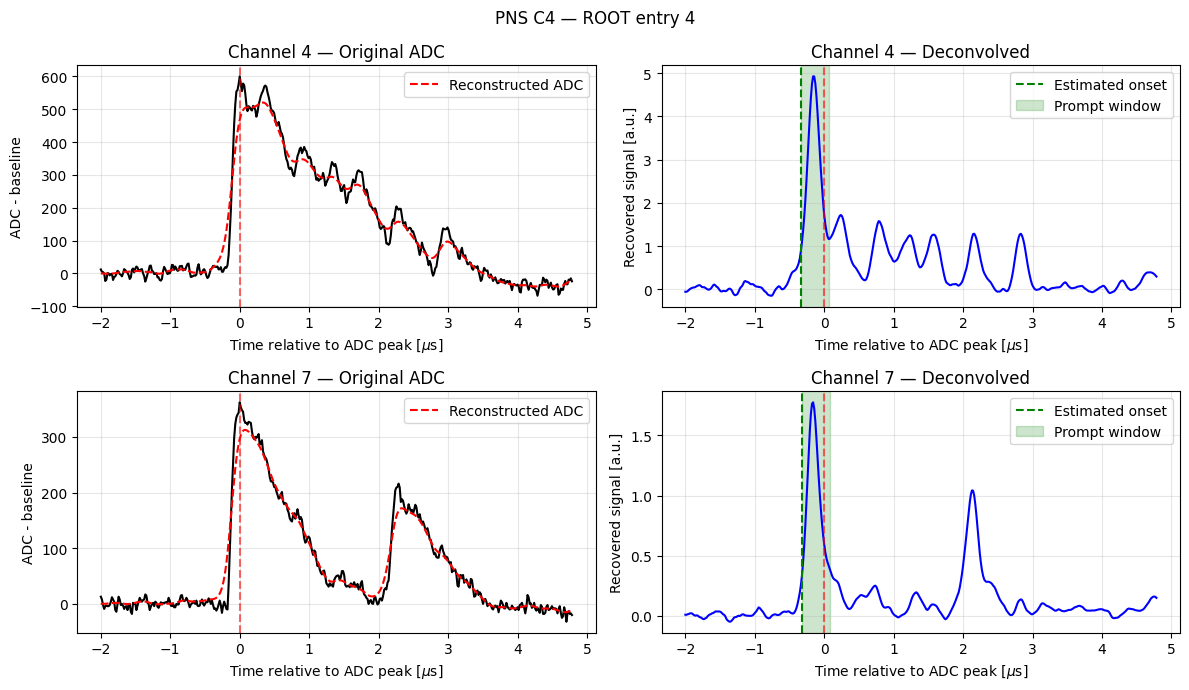

In [76]:
# Select first accepted PNS C4 coincidence
filename, entry, t4, t7 = cosmic_c4[revent]

with uproot.open(filename) as f:
    raw = f[cos_tree].arrays(
        ["DAQch_ID", "waveformsADC"],
        entry_start=entry,
        entry_stop=entry+1,
        library="ak"
    )

ids = np.asarray(raw["DAQch_ID"][0], dtype=int)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for row, (channel, tp) in enumerate([(4, t4), (7, t7)]):

    idx = np.where(ids == channel)[0][0]

    wf = np.asarray(
        raw["waveformsADC"][0][idx],
        dtype=float
    )

    pk = round(tp / DT)

    start = pk - before_peak
    stop = pk + after_peak

    baseline_start = pk - round(2.0 / DT) #2ms
    baseline_stop  = pk - round(1.0 / DT) #1ms

    baseline = np.median(wf[baseline_start:baseline_stop])
    #baseline = np.median(wf[pk-125:pk-62])

    waveform = wf[start:stop] - baseline

    # Apply SPE deconvolution
    recovered = deconvolve(
        waveform,
        spe_templates[channel]
    )
    # Reconstruct the ADC waveform from the deconvolved signal
    reconstructed = np.convolve(
        recovered,
        spe_templates[channel],
        mode="full"
    )[:len(waveform)]

    time = (np.arange(start, stop) - pk) * DT

    # Estimate baseline of the deconvolved signal
    signal = recovered - np.median(recovered[time < -0.8])

    # Find main recovered peak near the original ADC peak
    region = np.where((time >= -0.5) & (time <= 0.2))[0]
    imax = region[np.argmax(signal[region])]

    # if signal[imax] <= 0:
    #   return np.nan

    # Estimate onset at 15% of the recovered peak height
    before = region[region <= imax]
    crossing = before[signal[before] >= 0.15 * signal[imax]] 

    if len(crossing) > 0:

       i0 = crossing[0]

       # Integration windows (ms)
       prompt_window = 0.4
       total_window = 5.0

       # Convert ms to samples
       n_prompt = round(prompt_window / DT)
       n_total = round(total_window / DT)

       # Calculate charges 
       if i0 + n_total <= len(signal):

           q_prompt = np.sum(signal[i0:i0+n_prompt])
           #q_total = np.sum(signal[i0:i0+n_total])
           q_total = np.sum(signal[i0:])#i0+n_total])
 
           if q_total > 0 and 0 <= q_prompt <= q_total:

              fprompt = q_prompt / q_total

              print(f"Channel {channel}")
              print(f"Pulse onset: {time[i0]:.3f} µs")
              print(f"Prompt charge: {q_prompt:.3f}")
              print(f"Total charge: {q_total:.3f}")
              print(f"Deconvolved Fprompt: {fprompt:.3f}")

    # Original waveform
    axes[row, 0].plot(time, waveform, color="black")
    axes[row, 0].set_title(f"Channel {channel} — Original ADC")
    axes[row, 0].set_ylabel("ADC - baseline")

    axes[row, 0].plot(
    time, reconstructed,
    color="red", linestyle="--",
    label="Reconstructed ADC"
     )

    axes[row, 0].legend()

    # Deconvolved waveform
    axes[row, 1].plot(time, recovered, color="blue")
    axes[row, 1].set_title(f"Channel {channel} — Deconvolved")
    axes[row, 1].set_ylabel("Recovered signal [a.u.]")

    axes[row, 1].axvline(
                time[i0], color="green", ls="--",
                label="Estimated onset"
            )

    axes[row, 1].axvspan(
                time[i0], time[i0] + prompt_window,
                color="green", alpha=0.2,
                label="Prompt window"
            )

    axes[row, 1].legend()

    for ax in axes[row]:
        ax.axvline(0, color="red", ls="--", alpha=0.6)
        ax.set_xlabel(r"Time relative to ADC peak [$\mu$s]")
        ax.grid(alpha=0.3)

plt.suptitle(f"PNS C4 — ROOT entry {entry}")
plt.tight_layout()
plt.savefig('spe.png')
plt.show()

## PSD 

In [77]:
DT = 0.016  # µs

def calculate_deconv_psd(wf, peak_time, channel):

    pk = round(peak_time / DT)

    if pk < before_peak or pk + after_peak > len(wf):
        return np.nan, np.nan

    start = pk - before_peak
    stop = pk + after_peak # 375

    baseline_start = pk - round(2.0 / DT) #2ms
    baseline_stop  = pk - round(1.0 / DT) #1ms

    # Baseline subtraction
    baseline = np.median(wf[baseline_start:baseline_stop])
    waveform = wf[start:stop] - baseline

    # SPE deconvolution 
    recovered = deconvolve(
        waveform,
        spe_templates[channel]
    )

    time = (np.arange(start, stop) - pk) * DT

    # Baseline of recovered signal
    signal = recovered - np.median(recovered[time < -0.8])

    # Find main peak
    region = np.where((time >= -0.5) & (time <= 0.2))[0]
    imax = region[np.argmax(signal[region])]

    if signal[imax] <= 0:
        return np.nan, np.nan

    # Find pulse onset at 20% of maximum
    before = region[region <= imax]
    crossing = before[signal[before] >= 0.15 * signal[imax]]

    if len(crossing) == 0:
        return np.nan, np.nan

    i0 = crossing[0]
    #i0 = imax

    # Integration windows (ms)
    prompt_window = 0.4
    total_window = 5.0

    # Convert ms to samples
    n_prompt = round(prompt_window / DT)
    n_total = round(total_window / DT)
 
    if i0 + n_total > len(signal):
        return np.nan, np.nan

    q_prompt = np.sum(signal[i0:i0+n_prompt])
    q_total = np.sum(signal[i0:i0+n_total]) 
    #q_total = np.sum(signal[i0:]) # total integral

    if q_total <= 0 or not (0 <= q_prompt <= q_total):
        return np.nan, np.nan

    return q_total, q_prompt / q_total

In [80]:
def collect_deconv_psd(selected_events, tree_path):

    results = {4: [], 7: []}

    # Group the selected signals by ROOT file
    files = {}

    for filename, entry, t4, t7 in selected_events:
        files.setdefault(filename, []).append((entry, t4, t7))

    for filename, events in files.items():

        with uproot.open(filename) as f:

            tree = f[tree_path]

            for entry, t4, t7 in events:

                raw = tree.arrays(
                    ["DAQch_ID", "waveformsADC"],
                    entry_start=entry,
                    entry_stop=entry+1,
                    library="ak"
                )

                ids = np.asarray(raw["DAQch_ID"][0], dtype=int)

                fp = {}

                for channel, tp in [(4, t4), (7, t7)]:

                    idx = np.where(ids == channel)[0]

                    if len(idx) == 0:
                        fp[channel] = np.nan
                        continue

                    wf = np.asarray(
                        raw["waveformsADC"][0][idx[0]],
                        dtype=float
                    )

                    fp[channel] = calculate_deconv_psd(
                        wf, tp, channel
                    )

                # Require valid PSD in both channels
                #if np.isfinite(fp[4]) and np.isfinite(fp[7]):
                if all(np.all(np.isfinite(fp[ch])) for ch in [4, 7]):  # If q_total is inclued     

                    results[4].append(fp[4])
                    results[7].append(fp[7])

        print("Finished:", filename)

    return results

In [81]:
pns_deconv_psd = collect_deconv_psd(pns_c4, pns_tree)

cosmic_deconv_psd = collect_deconv_psd(cosmic_c4, cos_tree)

Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_pns_25050_0_5.root
Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_pns_25050_10_15.root
Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_pns_25050_16_19.root
Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_pns_25050_6_9.root
Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_cosmic_25066_0_5.root
Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_cosmic_25066_10_15.root
Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_cosmic_25066_16_19.root
Finished: /Users/rtluanga/myenv/NeutronLab/LED/ana_cosmic_25066_6_9.root


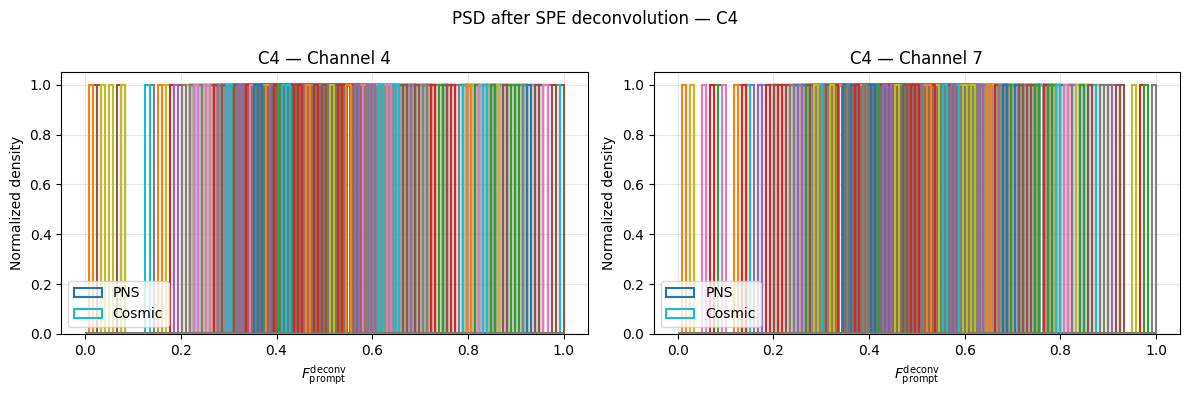

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(0, 1, 120)

for ax, channel in zip(axes, [4, 7]):

    ax.hist(
        pns_deconv_psd[channel],
        bins=bins,
        histtype="step",
        linewidth=1.5,
        density=False,
        label="PNS"
    )

    ax.hist(
        cosmic_deconv_psd[channel],
        bins=bins,
        histtype="step",
        linewidth=1.5,
        density=False,
        label="Cosmic"
    )

    ax.set_title(f"C4 — Channel {channel}")
    ax.set_xlabel(r"$F_{\mathrm{prompt}}^{\mathrm{deconv}}$")
    ax.set_ylabel("Normalized density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("PSD after SPE deconvolution — C4")
plt.tight_layout()
plt.show()

#### Normalized

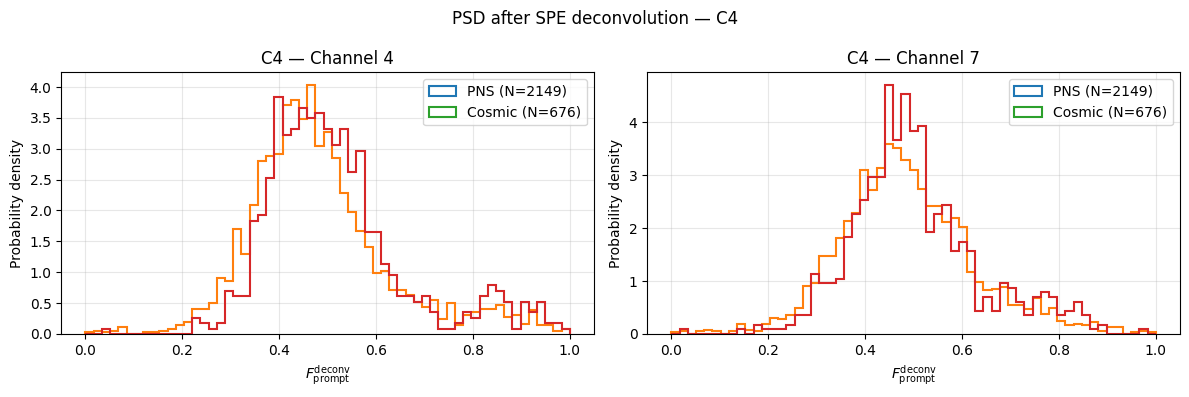

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(0, 1, 60)

for ax, channel in zip(axes, [4, 7]):

    pns = np.asarray(pns_deconv_psd[channel])
    cosmic = np.asarray(cosmic_deconv_psd[channel])

    ax.hist(
        pns,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=1.5,
        label=f"PNS (N={len(pns)})"
    )

    ax.hist(
        cosmic,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=1.5,
        label=f"Cosmic (N={len(cosmic)})"
    )

    ax.set_title(f"C4 — Channel {channel}")
    ax.set_xlabel(r"$F_{\mathrm{prompt}}^{\mathrm{deconv}}$")
    ax.set_ylabel("Probability density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("PSD after SPE deconvolution — C4")
plt.tight_layout()
plt.show()

### Integral vs Fp

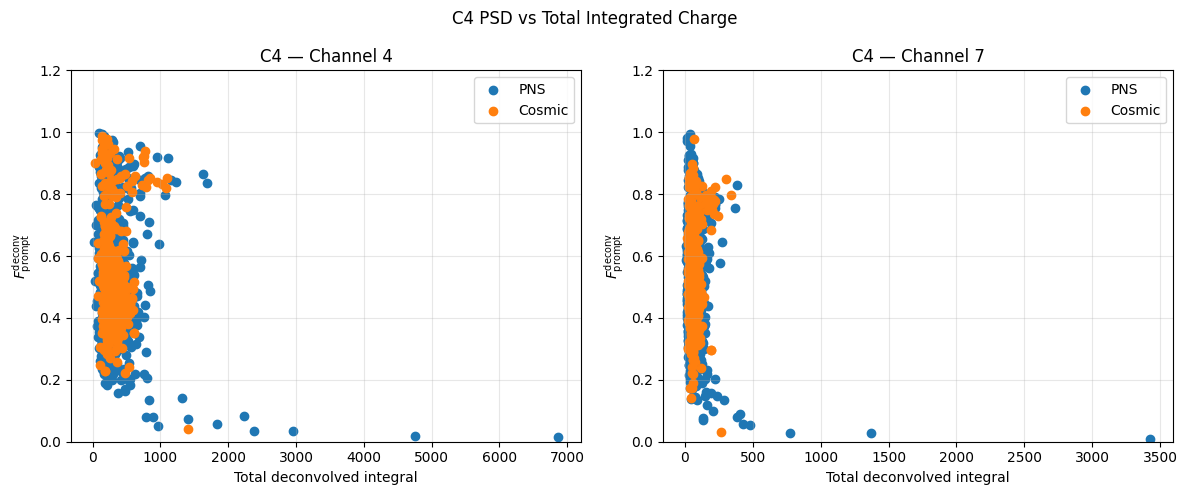

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, channel in zip(axes, [4, 7]):

    #pns = np.asarray(pnscosmic_deconv_psd[channel]).reshape(-1, 2)
    #cosmic = np.asarray(cosmic_deconv_psd[channel]).reshape(-1, 2)
    pns = np.asarray(pns_deconv_psd[channel])
    cosmic = np.asarray(cosmic_deconv_psd[channel])

    ax.scatter(pns[:, 0], pns[:, 1], label="PNS")
    ax.scatter(cosmic[:, 0], cosmic[:, 1], label="Cosmic")

    # Column 0 = total integral
    # Column 1 = Fprompt

    # ax.scatter(
    #     pns[:, 0], pns[:, 1],
    #     s=10, alpha=0.3,
    #     color="blue",
    #     label=f"PNS (N={len(pns)})"
    # )

    # ax.scatter(
    #     cosmic[:, 0], cosmic[:, 1],
    #     s=10, alpha=0.3,
    #     color="red",
    #     label=f"Cosmic (N={len(cosmic)})"
    # )

    ax.set_title(f"C4 — Channel {channel}")
    ax.set_xlabel("Total deconvolved integral")
    ax.set_ylabel(r"$F_{\mathrm{prompt}}^{\mathrm{deconv}}$")
    ax.set_ylim(0, 1.2)
    #ax.set_xscale('log')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("C4 PSD vs Total Integrated Charge")
plt.tight_layout()
plt.show()

# debug

In [228]:
for channel in [4, 7]:

    print(f"\nChannel {channel}")

    for name, df in [
        ("PNS", pns_peak_study),
        ("Cosmic", cosmic_peak_study)
    ]:

        groups = {
            "No late peak": df[~df["has_late"]],
            "Unaligned late peak": df[
                df["has_late"] & ~df["aligned_late"]
            ],
            "Aligned late peaks": df[df["aligned_late"]]
        }

        for label, group in groups.items():

            fp = group[f"fp{channel}"]

            if len(fp):
                print(
                    f"{name:6s} | {label:20s} | "
                    f"N={len(fp):4d} | "
                    f"Median Fp={fp.median():.3f}"
                )


Channel 4
PNS    | No late peak         | N= 904 | Median Fp=0.495
PNS    | Unaligned late peak  | N=1153 | Median Fp=0.409
PNS    | Aligned late peaks   | N=  92 | Median Fp=0.332
Cosmic | No late peak         | N= 346 | Median Fp=0.525
Cosmic | Unaligned late peak  | N= 318 | Median Fp=0.423
Cosmic | Aligned late peaks   | N=  15 | Median Fp=0.350

Channel 7
PNS    | No late peak         | N= 904 | Median Fp=0.503
PNS    | Unaligned late peak  | N=1153 | Median Fp=0.405
PNS    | Aligned late peaks   | N=  92 | Median Fp=0.338
Cosmic | No late peak         | N= 346 | Median Fp=0.500
Cosmic | Unaligned late peak  | N= 318 | Median Fp=0.414
Cosmic | Aligned late peaks   | N=  15 | Median Fp=0.381


## SPE timing check

Channel 4, 10%: sample 387, time relative to crop = 16.0 ns
Channel 4, 20%: sample 388, time relative to crop = 32.0 ns
Channel 4, SPE peak: sample 394, delay from crop = 128.0 ns
Channel 7, 10%: sample 387, time relative to crop = 16.0 ns
Channel 7, 20%: sample 388, time relative to crop = 32.0 ns
Channel 7, SPE peak: sample 395, delay from crop = 144.0 ns


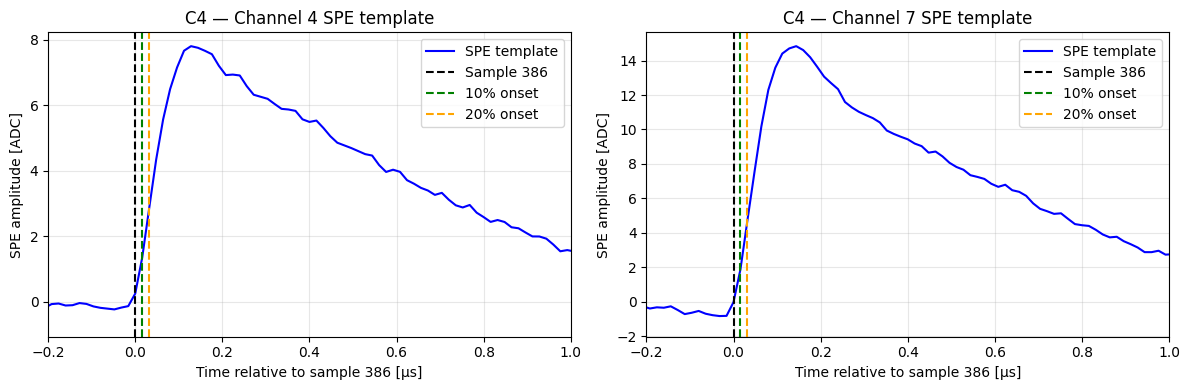

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import uproot

DT = 0.016  # µs

spe_folder = "/Users/rtluanga/myenv/NeutronLab/LED/Calibration_Ajib"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (channel, led_channel) in zip(axes, [(4, 0), (7, 7)]):

    filename = f"{spe_folder}/C4_AFE3_ch{led_channel}_SPE.root"

    with uproot.open(filename) as f:
        spe, edges = f["SPEtemplate_ns"].to_numpy()

    # Remove SPE baseline
    spe = spe - np.mean(spe[250:350])

    # Find SPE maximum near the known LED pulse
    imax = 375 + np.argmax(spe[375:450])

    # Time relative to our current cropping point
    time = (np.arange(len(spe)) - 386) * DT

    ax.plot(time, spe, color="blue", label="SPE template")

    # Current cropping point
    ax.axvline(0, color="black", ls="--", label="Sample 386")

    # Find 10% and 20% threshold crossings
    for fraction, color in [(0.10, "green"), (0.20, "orange")]:

        before = np.arange(375, imax + 1)

        crossing = before[
            spe[before] >= fraction * spe[imax]
        ]

        if len(crossing):
            i0 = crossing[0]

            ax.axvline(
                time[i0],
                color=color,
                ls="--",
                label=f"{int(fraction*100)}% onset"
            )

            print(
                f"Channel {channel}, {int(fraction*100)}%: "
                f"sample {i0}, "
                f"time relative to crop = {time[i0]*1000:.1f} ns"
            )

    print(
        f"Channel {channel}, SPE peak: sample {imax}, "
        f"delay from crop = {time[imax]*1000:.1f} ns"
    )

    ax.set_title(f"C4 — Channel {channel} SPE template")
    ax.set_xlim(-0.2, 1.0)
    ax.set_xlabel("Time relative to sample 386 [µs]")
    ax.set_ylabel("SPE amplitude [ADC]")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## No coincidence

In [71]:
# import numpy as np
# import uproot
# import matplotlib.pyplot as plt

# def collect_single_channel_psd(files, tree_path, min_pe=15):

#     results = {4: [], 7: []}
#     candidates = {4: 0, 7: 0}

#     for filename in sorted(files):

#         with uproot.open(filename) as f:

#             tree = f[tree_path]

#             # Read reconstructed optical peak information
#             peaks = tree.arrays(
#                 ["vtime", "vchannel", "vpeak"],
#                 library="ak"
#             )

#             for entry in range(len(peaks["vtime"])):

#                 times = np.asarray(peaks["vtime"][entry], dtype=float)
#                 channels = np.asarray(peaks["vchannel"][entry], dtype=int)
#                 pe = np.asarray(peaks["vpeak"][entry], dtype=float)

#                 # Select Ch 4 and Ch 7 independently
#                 mask = (
#                     np.isin(channels, [4, 7])
#                     & np.isfinite(times)
#                     & np.isfinite(pe)
#                     & (pe >= min_pe)
#                 )

#                 if not np.any(mask):
#                     continue

#                 # Read waveforms only for events with selected peaks
#                 raw = tree.arrays(
#                     ["DAQch_ID", "waveformsADC"],
#                     entry_start=entry,
#                     entry_stop=entry + 1,
#                     library="ak"
#                 )

#                 ids = np.asarray(raw["DAQch_ID"][0], dtype=int)

#                 for channel in [4, 7]:

#                     selected_times = times[
#                         mask & (channels == channel)
#                     ]

#                     if len(selected_times) == 0:
#                         continue

#                     idx = np.where(ids == channel)[0]

#                     if len(idx) == 0:
#                         continue

#                     wf = np.asarray(
#                         raw["waveformsADC"][0][idx[0]],
#                         dtype=float
#                     )

#                     # Calculate PSD for every selected pulse
#                     for tp in selected_times:

#                         candidates[channel] += 1

#                         fp = calculate_deconv_psd(
#                             wf, tp, channel
#                         )

#                         if np.isfinite(fp):
#                             results[channel].append(fp)

#         print("Finished:", filename)

#     for channel in [4, 7]:
#         print(
#             f"Ch {channel}: "
#             f"{len(results[channel])}/{candidates[channel]} "
#             "valid pulses"
#         )

#     return results

In [70]:
# pns_single_psd = collect_single_channel_psd(
#     pns_files, pns_tree
# )

# cosmic_single_psd = collect_single_channel_psd(
#     cos_files, cos_tree
# )